# Week 1 diagnostic — plant operations

## Goal

This ungraded tutorial checks readiness in Python, pandas, plotting,
interpretation, data-quality reasoning, and repository use. Do not hide gaps:
they identify what support will be useful before Week 3.

Work from the project folder supplied for your role. Do not edit the raw CSV.

## Setup

Run the environment checks in the README first. This cell locates the project
root from either the root folder or its `notebooks/` directory, then reads the
configured data path.

In [8]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt


def locate_project_root(start):
    candidates = (start, *start.parents)
    for candidate in candidates:
        if (candidate / 'config' / 'settings.yaml').exists():
            return candidate
    raise FileNotFoundError(
        'Project root not found. Change into the week01 project folder and rerun.'
    )


PROJECT_ROOT = locate_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from loading import DEFAULT_DATA  # noqa: E402

DATA = DEFAULT_DATA
print(f'Project root: {PROJECT_ROOT}')
print(f'Data source: {DATA.relative_to(PROJECT_ROOT)}')

Project root: D:\AIDS\AIDC\week01
Data source: data\raw\plant_shift_log.csv


## Task 1 — Load and inspect

Load the CSV as `df`. Display the first five rows, shape, column names, and data
types.

In [10]:
df = pd.read_csv(DATA)

display(df.head())
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
print('Data types:')
print(df.dtypes)

,timestamp,line_id,shift,units_produced,downtime_min,energy_kwh,rejected_units,motor_temp_c
0,2026-01-12T06:00,Line_A,Day,395,5.3,156.2,4,74.4
1,2026-01-12T06:00,Line_B,Day,342,11.9,148.2,10,76.4
2,2026-01-12T06:00,Line_C,Day,401,7.8,171.5,9,74.1
3,2026-01-12T07:00,Line_A,Day,407,11.8,165.2,5,75.3
4,2026-01-12T07:00,Line_B,Day,375,11.4,147.5,10,77.6


Shape: (73, 8)
Columns: ['timestamp', 'line_id', 'shift', 'units_produced', 'downtime_min', 'energy_kwh', 'rejected_units', 'motor_temp_c']
Data types:
timestamp          object
line_id            object
shift              object
units_produced      int64
downtime_min      float64
energy_kwh        float64
rejected_units      int64
motor_temp_c      float64
dtype: object


## Task 2 — Select and summarise

1. Select observations where `units_produced` is greater than 420.
2. Count observations by `line_id`.
3. Build a line-level summary containing total units, mean downtime, total
   rejects, and total energy.

In [12]:
high_output = df[df['units_produced'] > 420]
print('Observations with units_produced > 420:')
display(high_output)

observations_by_line = df['line_id'].value_counts().sort_index()
print('Observation count by line_id:')
display(observations_by_line)

line_summary = df.groupby('line_id').agg(
    total_units=('units_produced', 'sum'),
    mean_downtime_min=('downtime_min', 'mean'),
    total_rejects=('rejected_units', 'sum'),
    total_energy_kwh=('energy_kwh', 'sum'),
)
print('Line-level summary:')
display(line_summary)

Observations with units_produced > 420:


,timestamp,line_id,shift,units_produced,downtime_min,energy_kwh,rejected_units,motor_temp_c
6,2026-01-12T08:00,Line_A,Day,454,3.9,165.7,3,75.1
9,2026-01-12T09:00,Line_A,Day,461,2.6,165.7,3,72.8
12,2026-01-12T10:00,Line_A,Day,437,7.9,167.4,5,74.9
15,2026-01-12T11:00,Line_A,Day,432,9.8,157.2,8,72.4
20,2026-01-12T12:00,Line_C,Day,433,12.6,170.1,3,76.5
21,2026-01-12T13:00,Line_A,Day,450,6.7,161.8,7,74.5
24,2026-01-12T14:00,Line_A,Day,429,6.0,169.9,8,71.7
27,2026-01-12T15:00,Line_A,Day,446,7.8,173.5,9,74.3
30,2026-01-12T16:00,Line_A,Day,461,1.7,165.7,4,75.5
33,2026-01-12T17:00,Line_A,Day,439,3.0,169.6,5,72.8


Observation count by line_id:


line_id
Line_A    24
Line_B    24
Line_C    25
Name: count, dtype: int64

Line-level summary:


,total_units,mean_downtime_min,total_rejects,total_energy_kwh
line_id,,,,
Line_A,10110,7.258333,159,3918.7
Line_B,8631,13.891667,234,3421.1
Line_C,9990,12.050000,104,4242.2


## Task 3 — Derive a useful measure

Add `rejection_rate_pct = 100 * rejected_units / units_produced`. Summarise its
mean by line.

In [18]:
df['rejection_rate_pct'] = 100 * df['rejected_units'] / df['units_produced']
rejection_rate_by_line = df.groupby('line_id')['rejection_rate_pct'].mean()
display(rejection_rate_by_line)

line_id
Line_A    1.583460
Line_B    2.719974
Line_C    1.044329
Name: rejection_rate_pct, dtype: float64

## Task 4 — Plot

Convert `timestamp` to a datetime. Plot total units produced by timestamp across
all lines. Add a clear title and axis labels.

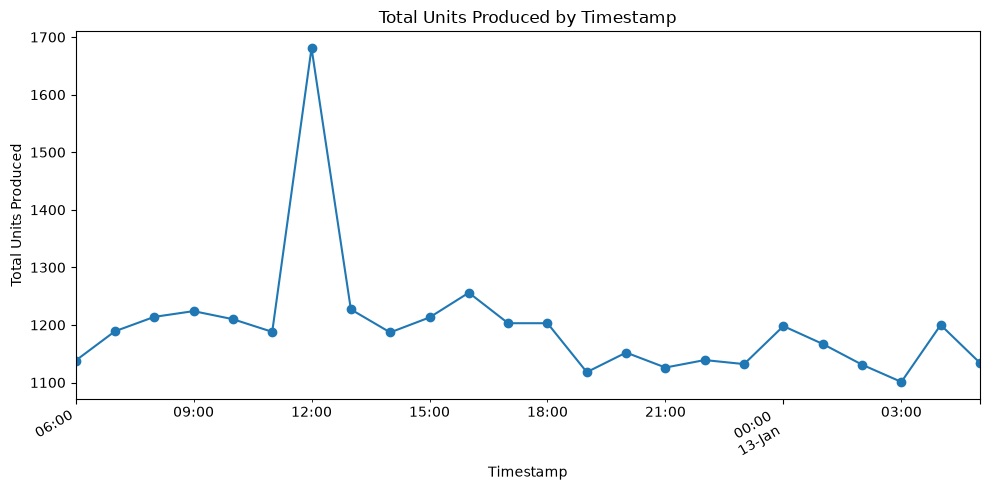

In [19]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
units_by_timestamp = df.groupby('timestamp')['units_produced'].sum().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
units_by_timestamp.plot(ax=ax, marker='o')
ax.set_title('Total Units Produced by Timestamp')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Total Units Produced')
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Task 5 — Interpret

Write **4–6 sentences** answering these questions:

- Which line appears most affected by downtime?
- Which line has the lowest average rejection rate?
- What can and cannot be concluded from this one-day simulated sample?

Line_B appears most affected by downtime, with the highest mean downtime at about 13.89 minutes per observation, compared with 12.05 for Line_C and 7.26 for Line_A. Line_C has the lowest average rejection rate at about 1.04%, while Line_B has the highest at about 2.72%. These results describe only the records in this one-day simulated sample. They highlight patterns worth investigating, but they do not establish that the differences persist over time or identify their causes. More representative data from additional days, together with operational context, would be needed before generalizing or making production decisions.

## Task 6 — Check data quality

Without repairing the raw data, identify at least two records or patterns that
deserve investigation. Useful methods include `duplicated()`, `isna()`,
`describe()`, and targeted filters.

In [17]:
print('Missing values by column:')
display(df.isna().sum())

key_columns = ['timestamp', 'line_id', 'shift']
duplicate_mask = df.duplicated(subset=key_columns, keep=False)
print('Records sharing a timestamp, line, and shift (review; not removed):')
display(df.loc[duplicate_mask].sort_values(key_columns))

expected_lines = df['line_id'].nunique()
records_per_timestamp = df.groupby('timestamp').size()
unusual_timestamps = records_per_timestamp[records_per_timestamp != expected_lines]
print('Timestamps with a record count different from the number of lines:')
display(unusual_timestamps)

numeric_columns = [
    'units_produced', 'downtime_min', 'energy_kwh',
    'rejected_units', 'motor_temp_c',
]
review_mask = (
    df['downtime_min'].isna()
    | (df['energy_kwh'] < 0)
    | (df['motor_temp_c'] > 100)
)
print('Records with missing downtime, negative energy, or motor temperature > 100 C:')
display(df.loc[review_mask, key_columns + numeric_columns])

print('Numeric field summary:')
display(df[numeric_columns].describe())

Missing values by column:


timestamp             0
line_id               0
shift                 0
units_produced        0
downtime_min          1
energy_kwh            0
rejected_units        0
motor_temp_c          0
rejection_rate_pct    0
dtype: int64

Records sharing a timestamp, line, and shift (review; not removed):


,timestamp,line_id,shift,units_produced,downtime_min,energy_kwh,rejected_units,motor_temp_c,rejection_rate_pct
20,2026-01-12 12:00:00,Line_C,Day,433,12.6,170.1,3,76.5,0.692841
72,2026-01-12 12:00:00,Line_C,Day,433,12.6,170.1,3,76.5,0.692841


Timestamps with a record count different from the number of lines:


timestamp
2026-01-12 12:00:00    4
dtype: int64

Records with missing downtime, negative energy, or motor temperature > 100 C:


,timestamp,line_id,shift,units_produced,downtime_min,energy_kwh,rejected_units,motor_temp_c
11,2026-01-12 09:00:00,Line_C,Day,407,NaN,171.5,3,76.2
40,2026-01-12 19:00:00,Line_B,Night,319,21.4,-12.0,11,74.6
55,2026-01-13 00:00:00,Line_B,Night,388,5.3,153.1,9,112.0


Numeric field summary:


,units_produced,downtime_min,energy_kwh,rejected_units,motor_temp_c
count,73.000000,72.000000,73.000000,73.000000,73.000000
mean,393.575342,11.066667,158.657534,6.808219,75.606849
std,33.521932,4.745584,22.492072,2.937580,4.622359
min,319.000000,1.300000,-12.000000,1.000000,71.300000
25%,366.000000,7.800000,152.200000,4.000000,74.100000
50%,396.000000,11.600000,163.000000,7.000000,75.000000
75%,415.000000,13.250000,169.000000,9.000000,76.500000
max,461.000000,21.900000,177.200000,13.000000,112.000000


## Task 7 — Frame the decision system

Complete `docs/problem_statement.md`. The provisional draft must name a user,
a decision, the available evidence, intended value, one important risk, and one
assumption that must be checked.


`docs/problem_statement.md` is complete. It names the user, inspection-prioritization decision, available evidence, intended value, operational risk, and the assumption that hourly measurements are accurate and comparable across lines.

## Task 8 — Demonstrate command-line and Git readiness

Save this notebook and the completed problem statement. From the project root,
run the following in a terminal:

```bash
git status
git add docs/problem_statement.md docs/readiness_note.md notebooks/week1_diagnostic.ipynb
git commit -m "Complete Week 1 diagnostic and problem statement"
git log -1 --oneline
git status
```

The course repository is read-only in Week 1, so stop after the commit. Your
commit stays local and that is the expected result. `git push` joins the loop
in Week 2, when you receive your own repository.

Never paste passwords, personal access tokens, or other credentials into this
notebook.


### Git evidence

Record the commit hash and the push status in `docs/readiness_note.md`, not here.
That file is one of the four Week 1 outputs.


## Next steps

Review any gaps with the instructor or teaching assistant. Suggested support
may include short Python/pandas practice, command-line/Git orientation, or a
brief follow-up before Week 3.